# Two thermal zones with one temperature measurement

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/10-observer-control/notebook.ipynb)

## Goal
Two hypothetical thermal zones obey $\dot x=Ax+Bu$ and $y=Cx$, with

$$
A=\begin{bmatrix}-0.15&0.05\\0.05&-0.10\end{bmatrix}\,\mathrm{s^{-1}},
\quad B=\begin{bmatrix}0.1\\0\end{bmatrix}\,\mathrm{K/(s\,W)},
\quad C=\begin{bmatrix}0&1\end{bmatrix}.
$$

Check controllability and observability. Choose feedback poles $-0.20,-0.35$, observer poles $-0.8,-1.0$ and a constant reference prefilter. Starting at $x(0)=[0.6,-0.4]^{\mathsf T}\,\mathrm{K}$ with zero estimate, regulate zone 2 to a $1\,\mathrm{K}$ rise.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/10-observer-control/figures/physical-system.png)

Two thermal inventories are connected by a conductive bridge. Heating acts in the first zone and sensing in the second. These stated capacities and conductances reproduce the two-state model exactly under the lumped assumptions.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/10-observer-control/exercises.pdf) accompany this model.

The equipment view includes state and unit labels, governing balances and interpretation limits. [Vector PDF](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/10-observer-control/figures/physical-system.pdf) · [Editable TikZ](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/10-observer-control/figures/physical-system.tikz).


## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/10-observer-control/figures/system-diagram.png)

The observer receives both the applied control and measured output. Its estimated vector supplies state feedback; the prefilter sets nominal reference gain.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### What can be controlled and observed?
The controllability matrix $[B\ AB]$ has determinant $0.0005$, while the observability matrix $[C;CA]$ for $C=[0\ 1]$ has determinant $-0.05$. Both are nonsingular. Heat injected into zone 1 can influence zone 2 through coupling, and the measured zone-2 temperature reveals the other state dynamically.
### Feedback and prefilter
Choose $u=-K\hat x+Nr$. Pole placement yields $K$ such that $A-BK$ has eigenvalues $-0.20,-0.35$. For constant references,

$$
N=-\left[C(A-BK)^{-1}B\right]^{-1}.
$$

This formula gives unit DC reference gain only for the nominal model and no constant disturbance. It is not integral regulation.
### Observer and separation
Use $\dot{\hat x}=A\hat x+Bu+L(y-C\hat x)$ and select $L$ by placing the eigenvalues of $A-LC$ at $-0.8,-1.0$. With error $e=x-\hat x$,

$$
\begin{bmatrix}\dot x\\\dot e\end{bmatrix}=
\begin{bmatrix}A-BK&BK\\0&A-LC\end{bmatrix}\begin{bmatrix}x\\e\end{bmatrix}+
\begin{bmatrix}BN\\0\end{bmatrix}r.
$$

The block triangular matrix shows why controller and observer eigenvalues combine without changing each other in the nominal linear model.
### Interpretation and limits
Observer convergence can be faster than output regulation. Faster estimation is not free: sensor noise and unmodeled dynamics are amplified by aggressive observer gains. Heating/cooling limits and temperature-dependent heat transfer are omitted; negative incremental heat can require an active cooler or reduction from a positive bias.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
A=np.array([[-.15,.05],[.05,-.10]]); B=np.array([[.1],[0.]]); C=np.array([[0.,1.]])
assert np.linalg.matrix_rank(ct.ctrb(A,B))==2
assert np.linalg.matrix_rank(ct.obsv(A,C))==2
K=ct.place(A,B,[-.20,-.35]); observer=ct.place(A.T,C.T,[-.8,-1.]).T
prefilter=-1/float((C@np.linalg.solve(A-B@K,B))[0,0])
augmented=np.block([[A-B@K,B@K],[np.zeros((2,2)),A-observer@C]])
input_vector=np.r_[B[:,0]*prefilter,np.zeros(2)]
initial=np.array([.6,-.4,.6,-.4])
time=np.linspace(0,80,4001)
solution=solve_ivp(lambda t,z:augmented@z+input_vector,[0,80],initial,t_eval=time,rtol=1e-10,atol=1e-11).y
estimate=solution[:2]-solution[2:]
assert np.max(np.abs(np.poly(A-B@K)-np.poly([-.2,-.35])))<1e-10
assert np.max(np.abs(np.poly(A-observer@C)-np.poly([-.8,-1.])))<1e-10
assert np.linalg.norm(solution[2:,-1])<1e-8
assert abs(solution[1,-1]-1)<1e-5
print('Feedback K:',K.round(8)); print('Observer L:',observer.ravel().round(8)); print(f'Reference prefilter N={prefilter:.8f}')


Feedback K: [[3.  5.5]]
Observer L: [11.1   1.55]
Reference prefilter N=14.00000000


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

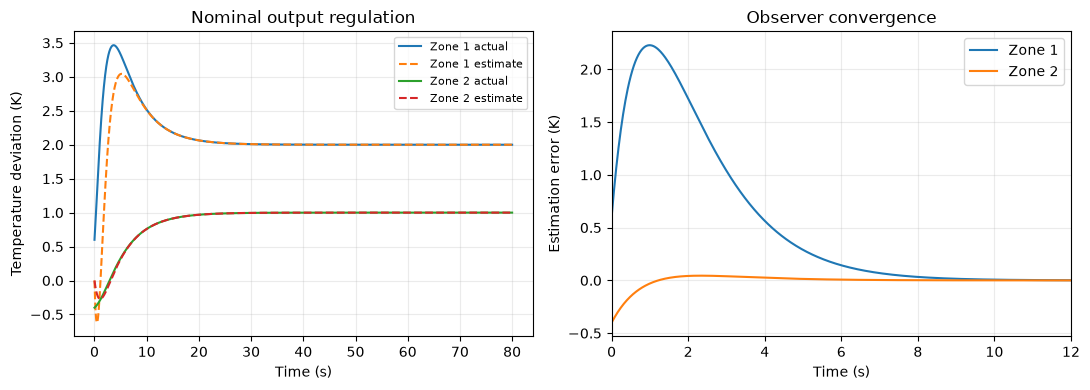

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for state in range(2):
    axes[0].plot(time,solution[state],label=f'Zone {state+1} actual'); axes[0].plot(time,estimate[state],'--',label=f'Zone {state+1} estimate')
    axes[1].plot(time,solution[state+2],label=f'Zone {state+1}')
axes[0].set(xlabel='Time (s)',ylabel='Temperature deviation (K)',title='Nominal output regulation'); axes[0].legend(fontsize=8)
axes[1].set(xlabel='Time (s)',ylabel='Estimation error (K)',title='Observer convergence',xlim=(0,12)); axes[1].legend()
fig.tight_layout()

plt.show()

## Interpret and extend
State estimation and reference prefiltering solve different problems. A nominal prefilter does not replace integral action against unknown constant disturbances.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)